<a href="https://colab.research.google.com/github/Nhut214/vietnamese_student_feedback_sentiment_analysis/blob/main/notebooks/01_Naive_Bayes_UIT_VSFC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install imbalanced-learn

Mounted at /content/drive
Đường dẫn dữ liệu: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/Data
Train: (11426, 3)
Validation: (1583, 3)
Test: (3166, 3)

Phân bố nhãn tập train:
sentiment
Negative    5325
Neutral      458
Positive    5643
Name: count, dtype: int64


,sentence,sentiment,topic
0,slide giáo trình đầy đủ .,2,1
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",2,0
2,đi học đầy đủ full điểm chuyên cần .,0,1
3,chưa áp dụng công nghệ thông tin và các thiết ...,0,0
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",2,0


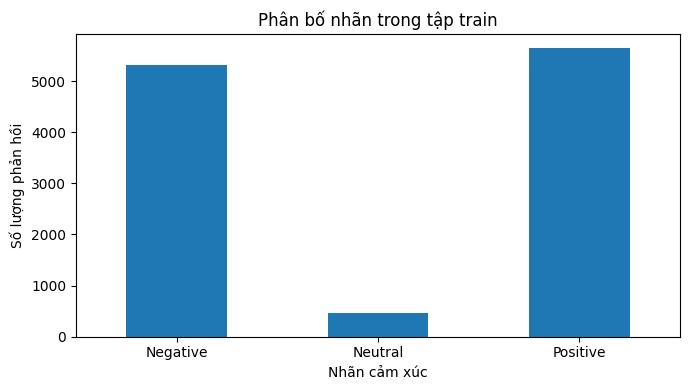

In [ ]:

from google.colab import drive
drive.mount("/content/drive")

import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

LABEL_IDS = [0, 1, 2]
LABEL_NAMES = ["Negative", "Neutral", "Positive"]
ID2LABEL = {0: "Negative", 1: "Neutral", 2: "Positive"}
LABEL2ID = {"Negative": 0, "Neutral": 1, "Positive": 2}

DATA_DIR = r"/content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/Data"

TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
VALIDATION_PATH = os.path.join(DATA_DIR, "validation.csv")
TEST_PATH = os.path.join(DATA_DIR, "test.csv")

for path in [TRAIN_PATH, VALIDATION_PATH, TEST_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Không tìm thấy file: {path}\n"
            "Hãy kiểm tra lại tên thư mục và tên file trong Google Drive."
        )

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VALIDATION_PATH)
test_df = pd.read_csv(TEST_PATH)

def clean_dataframe(df, name):
    required_columns = {"sentence", "sentiment"}
    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        raise ValueError(
            f"Tập {name} thiếu các cột bắt buộc: {missing_columns}"
        )

    cleaned = df.dropna(subset=["sentence", "sentiment"]).copy()
    cleaned["sentence"] = cleaned["sentence"].astype(str).str.strip()
    cleaned["sentiment"] = pd.to_numeric(
        cleaned["sentiment"],
        errors="coerce"
    )
    cleaned = cleaned.dropna(subset=["sentiment"])
    cleaned["sentiment"] = cleaned["sentiment"].astype(int)
    cleaned = cleaned[
        cleaned["sentiment"].isin(LABEL_IDS)
    ]
    cleaned = cleaned[
        cleaned["sentence"].str.len() > 0
    ].reset_index(drop=True)

    return cleaned

train_df = clean_dataframe(train_df, "train")
val_df = clean_dataframe(val_df, "validation")
test_df = clean_dataframe(test_df, "test")

# Các biến nhãn được tạo ngay sau khi đọc dữ liệu.
y_train = train_df["sentiment"].to_numpy(dtype=np.int64)
y_val = val_df["sentiment"].to_numpy(dtype=np.int64)
y_test = test_df["sentiment"].to_numpy(dtype=np.int64)

print("Đường dẫn dữ liệu:", DATA_DIR)
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nPhân bố nhãn tập train:")
print(
    train_df["sentiment"]
    .value_counts()
    .reindex(LABEL_IDS, fill_value=0)
    .rename(index=ID2LABEL)
)

display(train_df.head())

train_counts = (
    train_df["sentiment"]
    .value_counts()
    .reindex(LABEL_IDS, fill_value=0)
    .rename(index=ID2LABEL)
)

train_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Phân bố nhãn trong tập train")
plt.xlabel("Nhãn cảm xúc")
plt.ylabel("Số lượng phản hồi")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

RESULTS = []

def evaluate_predictions(
    model_name,
    experiment,
    y_true,
    y_pred,
    show_confusion_matrix=True
):
    accuracy = accuracy_score(y_true, y_pred)

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            average="macro",
            zero_division=0
        )
    )

    _, _, weighted_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=LABEL_IDS,
        average="weighted",
        zero_division=0
    )

    class_precision, class_recall, class_f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            average=None,
            zero_division=0
        )
    )

    result = {
        "Model": model_name,
        "Experiment": experiment,
        "Accuracy": accuracy,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Negative Precision": class_precision[0],
        "Negative Recall": class_recall[0],
        "Negative F1": class_f1[0],
        "Neutral Precision": class_precision[1],
        "Neutral Recall": class_recall[1],
        "Neutral F1": class_f1[1],
        "Positive Precision": class_precision[2],
        "Positive Recall": class_recall[2],
        "Positive F1": class_f1[2],
        "Neutral Support": int(support[1]),
    }

    RESULTS.append(result)

    print(f"\n{model_name} — {experiment}")
    print("=" * 72)
    print(
        classification_report(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            target_names=LABEL_NAMES,
            digits=4,
            zero_division=0
        )
    )

    if show_confusion_matrix:
        matrix = confusion_matrix(
            y_true,
            y_pred,
            labels=LABEL_IDS
        )
        display_matrix = ConfusionMatrixDisplay(
            matrix,
            display_labels=LABEL_NAMES
        )
        display_matrix.plot(values_format="d")
        plt.title(f"{model_name} — {experiment}")
        plt.tight_layout()
        plt.show()

    return result


def export_results(filename):
    if not RESULTS:
        raise ValueError("Chưa có kết quả để xuất.")

    result_df = (
        pd.DataFrame(RESULTS)
        .drop_duplicates(
            subset=["Model", "Experiment"],
            keep="last"
        )
        .reset_index(drop=True)
    )

    metric_columns = [
        column
        for column in result_df.columns
        if column not in [
            "Model",
            "Experiment",
            "Neutral Support"
        ]
    ]

    display_df = result_df.copy()
    display_df[metric_columns] = (
        display_df[metric_columns].round(4)
    )

    display(display_df)

    output_path = os.path.join(
        "/content/drive/MyDrive/NC_MatCanBang_UIT_VSFC",
        filename
    )
    result_df.to_csv(output_path, index=False)

    print("Đã lưu kết quả tại:", output_path)
    return result_df



## 1. Tạo đặc trưng TF-IDF

Sử dụng Uni-gram và Bi-gram. Bộ từ vựng chỉ được học từ tập train.


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from imblearn.over_sampling import RandomOverSampler

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=30000,
    sublinear_tf=True,
    lowercase=False
)

X_train = tfidf.fit_transform(
    train_df["sentence"].astype(str)
)
X_val = tfidf.transform(
    val_df["sentence"].astype(str)
)
X_test = tfidf.transform(
    test_df["sentence"].astype(str)
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

assert X_train.shape[0] == len(y_train)
assert X_val.shape[0] == len(y_val)
assert X_test.shape[0] == len(y_test)


X_train: (11426, 13154)
y_train: (11426,)
X_val: (1583, 13154)
y_val: (1583,)
X_test: (3166, 13154)
y_test: (3166,)



## 2. Naive Bayes trên dữ liệu gốc



Naive Bayes — Baseline
              precision    recall  f1-score   support

    Negative     0.8141    0.9354    0.8705      1409
     Neutral     0.0000    0.0000    0.0000       167
    Positive     0.9017    0.8767    0.8890      1590

    accuracy                         0.8566      3166
   macro avg     0.5719    0.6040    0.5865      3166
weighted avg     0.8151    0.8566    0.8339      3166



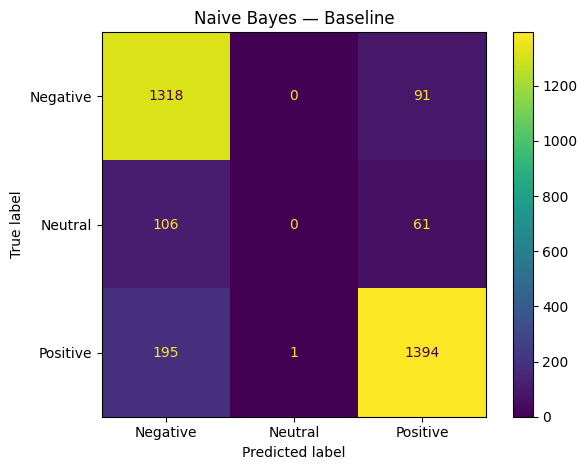

{'Model': 'Naive Bayes',
 'Experiment': 'Baseline',
 'Accuracy': 0.8566013897662665,
 'Macro Precision': 0.5719215088397509,
 'Macro Recall': 0.604048249275026,
 'Macro F1': 0.5865240746232443,
 'Weighted F1': 0.8339077082276627,
 'Negative Precision': np.float64(0.81408276714021),
 'Negative Recall': np.float64(0.9354151880766501),
 'Negative F1': np.float64(0.8705416116248349),
 'Neutral Precision': np.float64(0.0),
 'Neutral Recall': np.float64(0.0),
 'Neutral F1': np.float64(0.0),
 'Positive Precision': np.float64(0.9016817593790427),
 'Positive Recall': np.float64(0.8767295597484277),
 'Positive F1': np.float64(0.889030612244898),
 'Neutral Support': 167}

In [ ]:

model_nb_baseline = MultinomialNB(alpha=1.0)
model_nb_baseline.fit(X_train, y_train)

pred_nb_baseline = model_nb_baseline.predict(X_test)

evaluate_predictions(
    "Naive Bayes",
    "Baseline",
    y_test,
    pred_nb_baseline
)



## 3. Naive Bayes kết hợp Random Oversampling

Oversampling chỉ áp dụng cho tập train.


Phân bố trước oversampling: [5325  458 5643]
Phân bố sau oversampling: [5643 5643 5643]

Naive Bayes — Random Oversampling
              precision    recall  f1-score   support

    Negative     0.8370    0.8602    0.8484      1409
     Neutral     0.2491    0.4012    0.3073       167
    Positive     0.9248    0.8428    0.8819      1590

    accuracy                         0.8272      3166
   macro avg     0.6703    0.7014    0.6792      3166
weighted avg     0.8501    0.8272    0.8367      3166



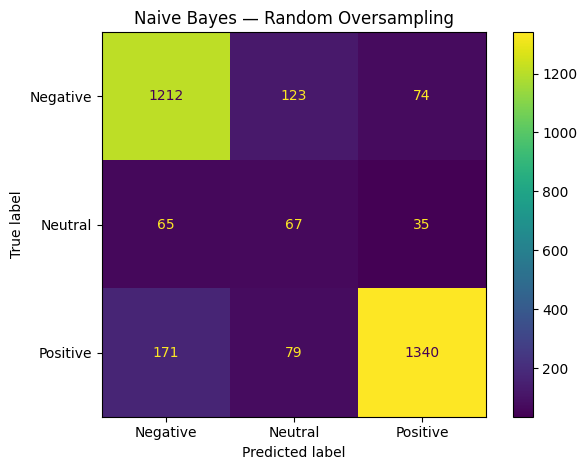

{'Model': 'Naive Bayes',
 'Experiment': 'Random Oversampling',
 'Accuracy': 0.8272267845862287,
 'Macro Precision': 0.6702876379800995,
 'Macro Recall': 0.7013831428073235,
 'Macro F1': 0.6792169691764839,
 'Weighted F1': 0.8366875640779095,
 'Negative Precision': np.float64(0.8370165745856354),
 'Negative Recall': np.float64(0.8601845280340668),
 'Negative F1': np.float64(0.8484424221211061),
 'Neutral Precision': np.float64(0.24907063197026022),
 'Neutral Recall': np.float64(0.40119760479041916),
 'Neutral F1': np.float64(0.3073394495412844),
 'Positive Precision': np.float64(0.9247757073844031),
 'Positive Recall': np.float64(0.8427672955974843),
 'Positive F1': np.float64(0.8818690358670616),
 'Neutral Support': 167}

In [ ]:

oversampler = RandomOverSampler(random_state=SEED)

X_train_oversampled, y_train_oversampled = (
    oversampler.fit_resample(
        X_train,
        y_train
    )
)

print(
    "Phân bố trước oversampling:",
    np.bincount(y_train)
)
print(
    "Phân bố sau oversampling:",
    np.bincount(y_train_oversampled)
)

model_nb_oversampled = MultinomialNB(alpha=1.0)
model_nb_oversampled.fit(
    X_train_oversampled,
    y_train_oversampled
)

pred_nb_oversampled = (
    model_nb_oversampled.predict(X_test)
)

evaluate_predictions(
    "Naive Bayes",
    "Random Oversampling",
    y_test,
    pred_nb_oversampled
)


In [ ]:

naive_bayes_results = export_results(
    "naive_bayes_results.csv"
)


,Model,Experiment,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Negative Precision,Negative Recall,Negative F1,Neutral Precision,Neutral Recall,Neutral F1,Positive Precision,Positive Recall,Positive F1,Neutral Support
0,Naive Bayes,Baseline,0.8566,0.5719,0.6040,0.5865,0.8339,0.8141,0.9354,0.8705,0.0000,0.0000,0.0000,0.9017,0.8767,0.8890,167
1,Naive Bayes,Random Oversampling,0.8272,0.6703,0.7014,0.6792,0.8367,0.8370,0.8602,0.8484,0.2491,0.4012,0.3073,0.9248,0.8428,0.8819,167


Đã lưu kết quả tại: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/naive_bayes_results.csv


In [ ]:
import os
import json

SAVE_DIR = (
    "/content/drive/MyDrive/"
    "NC_MatCanBang_UIT_VSFC/"
    "SavedModels/"
    "naive_bayes_ros"
)

os.makedirs(
    SAVE_DIR,
    exist_ok=True
)

NB_JSON_PATH = os.path.join(
    SAVE_DIR,
    "nb_model.json"
)

nb_data = {
    "model_type": "MultinomialNB",
    "scenario": "Random Oversampling",

    "labels": {
        "0": "Negative",
        "1": "Neutral",
        "2": "Positive"
    },

    "classes": [
        int(x)
        for x in model_nb_oversampled.classes_
    ],

    "alpha": float(
        model_nb_oversampled.alpha
    ),

    "class_log_prior": [
        float(x)
        for x in (
            model_nb_oversampled
            .class_log_prior_
        )
    ],

    "feature_log_prob": [
        [
            float(value)
            for value in row
        ]
        for row in (
            model_nb_oversampled
            .feature_log_prob_
        )
    ],

    "tfidf": {
        "vocabulary": {
            str(token): int(index)
            for token, index
            in tfidf.vocabulary_.items()
        },

        "idf": [
            float(x)
            for x in tfidf.idf_
        ],

        "ngram_range": [
            int(x)
            for x in tfidf.ngram_range
        ],

        "sublinear_tf": bool(
            tfidf.sublinear_tf
        ),

        "lowercase": bool(
            tfidf.lowercase
        ),

        "norm": str(tfidf.norm),

        "token_pattern": str(
            tfidf.token_pattern
        )
    }
}

with open(
    NB_JSON_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        nb_data,
        f,
        ensure_ascii=False
    )

print(
    "Đã lưu:",
    NB_JSON_PATH
)

print(
    "Dung lượng:",
    round(
        os.path.getsize(
            NB_JSON_PATH
        ) / (1024 ** 2),
        2
    ),
    "MB"
)

Đã lưu: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/SavedModels/naive_bayes_ros/nb_model.json
Dung lượng: 1.25 MB


In [ ]:
print(
    "Có file:",
    os.path.exists(NB_JSON_PATH)
)

print(
    "Số đặc trưng:",
    len(
        nb_data["tfidf"]["vocabulary"]
    )
)

print(
    "Số lớp:",
    len(nb_data["classes"])
)

Có file: True
Số đặc trưng: 13154
Số lớp: 3


In [ ]:
from huggingface_hub import login

login()

In [ ]:
from huggingface_hub import create_repo

REPO_ID = "hnhut/uit-vsfc-naive-bayes-ros"

create_repo(
    repo_id=REPO_ID,
    repo_type="model",
    private=False,
    exist_ok=True
)

print("Repository:", REPO_ID)

Repository: hnhut/uit-vsfc-naive-bayes-ros


In [ ]:
from huggingface_hub import upload_file

upload_file(
    path_or_fileobj=NB_JSON_PATH,
    path_in_repo="nb_model.json",
    repo_id=REPO_ID,
    repo_type="model",
    commit_message=(
        "Upload Naive Bayes ROS model"
    )
)

print(
    "Đã tải Naive Bayes lên Hugging Face:",
    REPO_ID
)

Đã tải Naive Bayes lên Hugging Face: hnhut/uit-vsfc-naive-bayes-ros
